In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [46]:
df = pd.read_csv('housing.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [47]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [48]:
df1 = df.copy()

In [49]:
median_bedrooms = df1['total_bedrooms'].median()
df1['total_bedrooms'] = df1['total_bedrooms'].fillna(median_bedrooms)


In [50]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20640 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [51]:
df1['ocean_proximity'].unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

In [52]:
df2 = df1.copy()

In [53]:
cat_feature = df2[['ocean_proximity']]

encoder = OneHotEncoder(sparse_output=False, drop=None)

encoded = encoder.fit_transform(cat_feature)
encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(['ocean_proximity']))
df2 = pd.concat([df2, encoded_df], axis=1)
print(df2.head())

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  \
0       322.0       126.0         8.3252            452600.0        NEAR BAY   
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY   
2       496.0       177.0         7.2574            352100.0        NEAR BAY   
3       558.0       219.0         5.6431            341300.0        NEAR BAY   
4       565.0       259.0         3.8462            342200.0        NEAR BAY   

   ocean_proximity_<1H OCEAN  ocean_proximity_INLAND  ocean_proximit

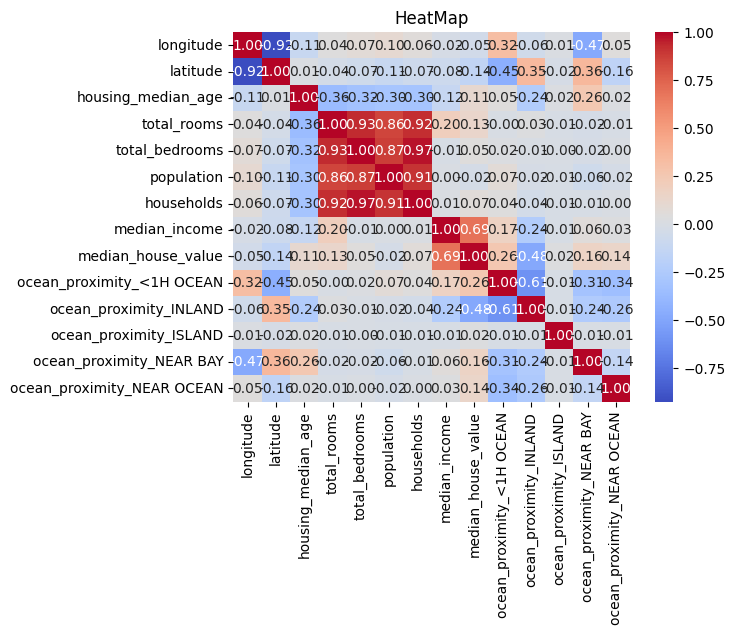

In [54]:
corr_matix = df2.corr(numeric_only=True)

plt.Figure(figsize=(10, 6))
sns.heatmap(corr_matix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("HeatMap")
plt.show();

In [55]:
df2['rooms_per_household'] = df2['total_rooms'] / df2['households']
df2['bedrooms_per_room']  = df2['total_bedrooms'] / df2['total_rooms']
df2['population_per_household'] = df2['population'] / df2['households']

df2.drop(["total_rooms", "total_bedrooms", "population", "households", 'ocean_proximity'], axis=1, inplace=True)

df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   median_income               20640 non-null  float64
 4   median_house_value          20640 non-null  float64
 5   ocean_proximity_<1H OCEAN   20640 non-null  float64
 6   ocean_proximity_INLAND      20640 non-null  float64
 7   ocean_proximity_ISLAND      20640 non-null  float64
 8   ocean_proximity_NEAR BAY    20640 non-null  float64
 9   ocean_proximity_NEAR OCEAN  20640 non-null  float64
 10  rooms_per_household         20640 non-null  float64
 11  bedrooms_per_room           20640 non-null  float64
 12  population_per_household    20640 non-null  float64
dtypes: float64(13)
memory usage: 2.

In [56]:
df2_skew = df2.skew(numeric_only=True).sort_values(ascending=False)
df2_skew

population_per_household      97.639561
ocean_proximity_ISLAND        64.230833
rooms_per_household           20.697869
bedrooms_per_room              6.316904
ocean_proximity_NEAR BAY       2.477658
ocean_proximity_NEAR OCEAN     2.216702
median_income                  1.646657
median_house_value             0.977763
ocean_proximity_INLAND         0.784682
latitude                       0.465953
ocean_proximity_<1H OCEAN      0.230999
housing_median_age             0.060331
longitude                     -0.297801
dtype: float64

In [57]:
from scipy.stats.mstats import winsorize
skew_cols = ['population_per_household', 'ocean_proximity_ISLAND', 'rooms_per_household']
for col in skew_cols:
    df2[col] = winsorize(df2[col], limits=[0.01, 0.01])

df2.skew(numeric_only=True)
df2[skew_cols].skew()

population_per_household    0.859758
ocean_proximity_ISLAND      0.000000
rooms_per_household         0.816510
dtype: float64

In [58]:
df2_skew = df2.skew(numeric_only=True).sort_values(ascending=False)
df2_skew

bedrooms_per_room             6.316904
ocean_proximity_NEAR BAY      2.477658
ocean_proximity_NEAR OCEAN    2.216702
median_income                 1.646657
median_house_value            0.977763
population_per_household      0.859758
rooms_per_household           0.816510
ocean_proximity_INLAND        0.784682
latitude                      0.465953
ocean_proximity_<1H OCEAN     0.230999
housing_median_age            0.060331
ocean_proximity_ISLAND        0.000000
longitude                    -0.297801
dtype: float64

In [59]:
df2['bedrooms_per_room'] = np.log1p(df2['bedrooms_per_room'])

print(df2.skew(numeric_only=True).sort_values(ascending=False))

bedrooms_per_room             2.796456
ocean_proximity_NEAR BAY      2.477658
ocean_proximity_NEAR OCEAN    2.216702
median_income                 1.646657
median_house_value            0.977763
population_per_household      0.859758
rooms_per_household           0.816510
ocean_proximity_INLAND        0.784682
latitude                      0.465953
ocean_proximity_<1H OCEAN     0.230999
housing_median_age            0.060331
ocean_proximity_ISLAND        0.000000
longitude                    -0.297801
dtype: float64


In [60]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   median_income               20640 non-null  float64
 4   median_house_value          20640 non-null  float64
 5   ocean_proximity_<1H OCEAN   20640 non-null  float64
 6   ocean_proximity_INLAND      20640 non-null  float64
 7   ocean_proximity_ISLAND      20640 non-null  float64
 8   ocean_proximity_NEAR BAY    20640 non-null  float64
 9   ocean_proximity_NEAR OCEAN  20640 non-null  float64
 10  rooms_per_household         20640 non-null  float64
 11  bedrooms_per_room           20640 non-null  float64
 12  population_per_household    20640 non-null  float64
dtypes: float64(13)
memory usage: 2.

In [62]:
from scipy.stats import zscore
z_score = df2.apply(zscore)
outliers = (np.abs(z_score) > 3)
outliers_count= outliers.sum()
print(outliers_count)

longitude                       0
latitude                        0
housing_median_age              0
median_income                 345
median_house_value              0
ocean_proximity_<1H OCEAN       0
ocean_proximity_INLAND          0
ocean_proximity_ISLAND          0
ocean_proximity_NEAR BAY        0
ocean_proximity_NEAR OCEAN      0
rooms_per_household           279
bedrooms_per_room             252
population_per_household      299
dtype: int64


In [63]:
from scipy.stats import boxcox

outliers_cols = ['median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
 
for col in outliers_cols:
    df2[col] = winsorize(df2[col], limits=[0.01, 0.01])
    
for col in outliers_cols:
    if (df2[col] <= 0).any():
        df2[col] = np.log1p(df2[col])
        print(f"Applied log1p on {col}")
    else:
        df2[col], _ = boxcox(df2[col])
        print(f"Applied Box-Cox on {col}")

skew_after = df2[outliers_cols].skew()
print("\n Skewness After Winsorization + Box-Cox:\n")
print(skew_after.sort_values(ascending=False))

Applied Box-Cox on median_income
Applied Box-Cox on rooms_per_household
Applied Box-Cox on bedrooms_per_room
Applied Box-Cox on population_per_household

 Skewness After Winsorization + Box-Cox:

rooms_per_household         0.004718
bedrooms_per_room           0.003387
population_per_household   -0.000921
median_income              -0.001830
dtype: float64


In [64]:
from scipy.stats import zscore
z_score = df2.apply(zscore)
outliers = (np.abs(z_score) > 3)
outliers_count= outliers.sum()
print(outliers_count)

longitude                     0
latitude                      0
housing_median_age            0
median_income                 0
median_house_value            0
ocean_proximity_<1H OCEAN     0
ocean_proximity_INLAND        0
ocean_proximity_ISLAND        0
ocean_proximity_NEAR BAY      0
ocean_proximity_NEAR OCEAN    0
rooms_per_household           0
bedrooms_per_room             0
population_per_household      0
dtype: int64


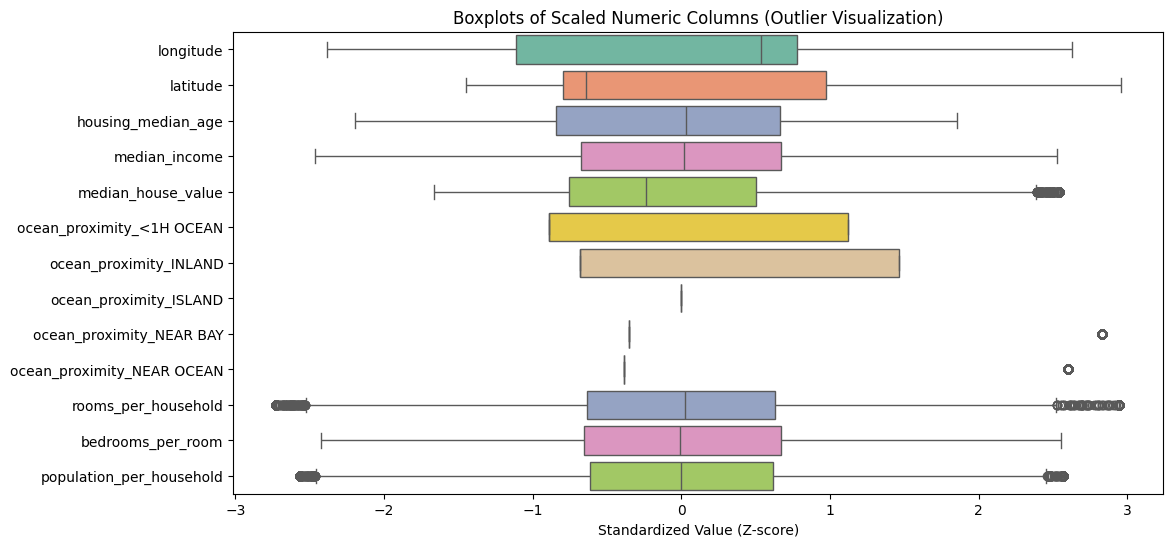

In [70]:
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns
numeric_cols = df2.select_dtypes(include=['float64', 'int64']).columns

# Standardize data (z-score scaling)
scaled_df = pd.DataFrame(StandardScaler().fit_transform(df2[numeric_cols]),
                         columns=numeric_cols)

# Plot scaled boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=scaled_df, orient='h', palette='Set2')
plt.title("Boxplots of Scaled Numeric Columns (Outlier Visualization)")
plt.xlabel("Standardized Value (Z-score)")
plt.show()


In [72]:
import plotly.express as px

fig = px.scatter(
    df2,
    x="longitude",
    y="latitude",
    color="median_house_value",
    color_continuous_scale="Viridis",
    title="California Housing Prices by Location",
    opacity=0.6,
    width=900,
    height=600
)
fig.update_layout(coloraxis_colorbar=dict(title="Median House Value ($)"))
fig.show()


In [73]:
from sklearn.cluster import KMeans

df2['distance_to_coast'] = df2['longitude'].max() - df2['longitude']

kmeans = KMeans(n_clusters=5, random_state=42)
df2['region_cluster'] = kmeans.fit_predict(df2[['latitude', 'longitude']])

df2['lat_long_interaction'] = df2['latitude'] * df2['longitude']

df2 = df2.drop(['longitude', 'latitude'],axis=1)

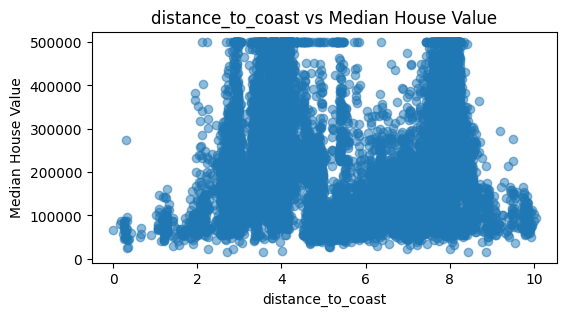

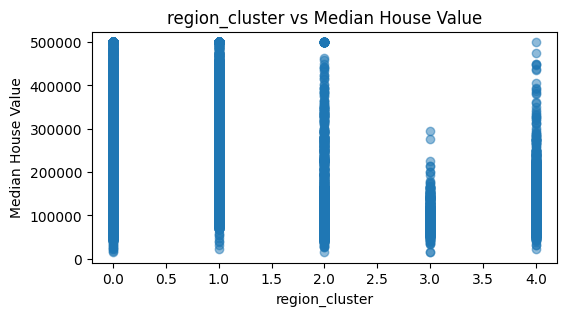

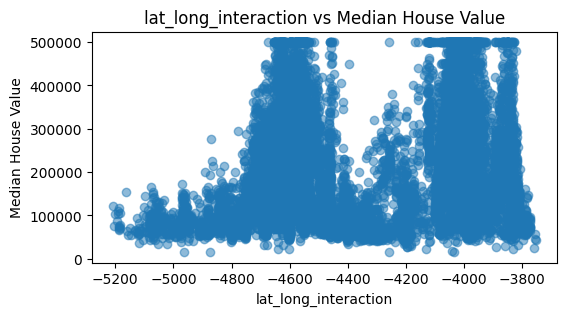

In [74]:

features = ['distance_to_coast', 'region_cluster', 'lat_long_interaction']
for col in features:
    plt.figure(figsize=(6,3))
    plt.scatter(df2[col], df2['median_house_value'], alpha=0.5)
    plt.title(f'{col} vs Median House Value')
    plt.xlabel(col)
    plt.ylabel('Median House Value')
    plt.show()


In [75]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   housing_median_age          20640 non-null  float64
 1   median_income               20640 non-null  float64
 2   median_house_value          20640 non-null  float64
 3   ocean_proximity_<1H OCEAN   20640 non-null  float64
 4   ocean_proximity_INLAND      20640 non-null  float64
 5   ocean_proximity_ISLAND      20640 non-null  float64
 6   ocean_proximity_NEAR BAY    20640 non-null  float64
 7   ocean_proximity_NEAR OCEAN  20640 non-null  float64
 8   rooms_per_household         20640 non-null  float64
 9   bedrooms_per_room           20640 non-null  float64
 10  population_per_household    20640 non-null  float64
 11  distance_to_coast           20640 non-null  float64
 12  region_cluster              20640 non-null  int32  
 13  lat_long_interaction        206

In [77]:
X = df2.drop(columns=['median_house_value'])
y = df2['median_house_value']
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2 ,random_state=42)
model = DecisionTreeRegressor(
    max_depth=8,
    min_samples_leaf=20,
    min_samples_split=50,
    random_state=42
)

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))
print("Train MSE:", np.sqrt(mean_squared_error(y_train, y_train_pred)))
print("Test MSE:", mean_squared_error(y_test, y_test_pred))


Train R2: 0.7714970134010084
Test R2: 0.7231861078139119
Train MSE: 55268.23805897412
Test MSE: 3627394096.2245827


In [81]:
from sklearn.metrics import root_mean_squared_error

test_mse = mean_squared_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_test, y_test_pred)

train_rmse = np.sqrt(train_mse)
test_rmse = np.sqrt(test_mse)

print("Train RMSE:", train_rmse)
print("Test RMSE:", test_rmse)



Train RMSE: 60227.85149932365
Test RMSE: 55268.23805897412


# HyperParameter Tunning

In [89]:
X = df2.drop(columns=['median_house_value'])
y = df2['median_house_value']


X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2 ,random_state=42)

tree = DecisionTreeRegressor(random_state=42)

param_grid = {
    'max_depth': [20],
    'min_samples_leaf': [10],
    'min_samples_split': [40]
}

grid_seach = GridSearchCV(
    estimator=tree,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_seach.fit(X_train, y_train)

print("Best Parameter:", grid_seach.best_params_)

Best Parameter: {'max_depth': 20, 'min_samples_leaf': 10, 'min_samples_split': 40}


In [ ]:
best_tree = grid_seach.best_estimator_
best_tree.fit(X_train, y_train)

y_train_pred = best_tree.predict(X_train)
y_test_pred = best_tree.predict(X_test)



def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))
print("Train RMSE:", root_mean_squared_error(y_train, y_train_pred))
print("Test RMSE:", root_mean_squared_error(y_test, y_test_pred))

Train R2: 0.8459688500850391
Test R2: 0.7521573925985167
Train RMSE: 45376.80962156669
Test RMSE: 56989.049643728766


In [96]:
X = df2.drop(columns=['median_house_value'])
y = df2['median_house_value']


y_log = np.log1p(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_log,test_size=0.2 ,random_state=42)

best_tree = DecisionTreeRegressor(
    max_depth=15,
    min_samples_leaf=20,
    min_samples_split=50,
    random_state=42
    )

best_tree.fit(X_train, y_train)

y_train_pred_log = best_tree.predict(X_train)
y_test_pred_log = best_tree.predict(X_test)

y_train_pred_log = np.clip(y_train_pred_log, a_min=None, a_max=15)
y_test_pred_log = np.clip(y_test_pred_log, a_min=None, a_max=15)

y_train_pred = np.expm1(y_train_pred_log)
y_test_pred = np.expm1(y_test_pred_log)

y_train_original = np.expm1(y_train)
y_test_original = np.expm1(y_test)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


print("Train R²:", r2_score(y_train_original, y_train_pred))
print("Test R²:", r2_score(y_test_original, y_test_pred))
print("Train RMSE:", root_mean_squared_error(y_train_original, y_train_pred))
print("Test RMSE:", root_mean_squared_error(y_test_original, y_test_pred))

Train R²: 0.8190802629928785
Test R²: 0.7471901989898989
Train RMSE: 49178.202744080954
Test RMSE: 57557.29606495874


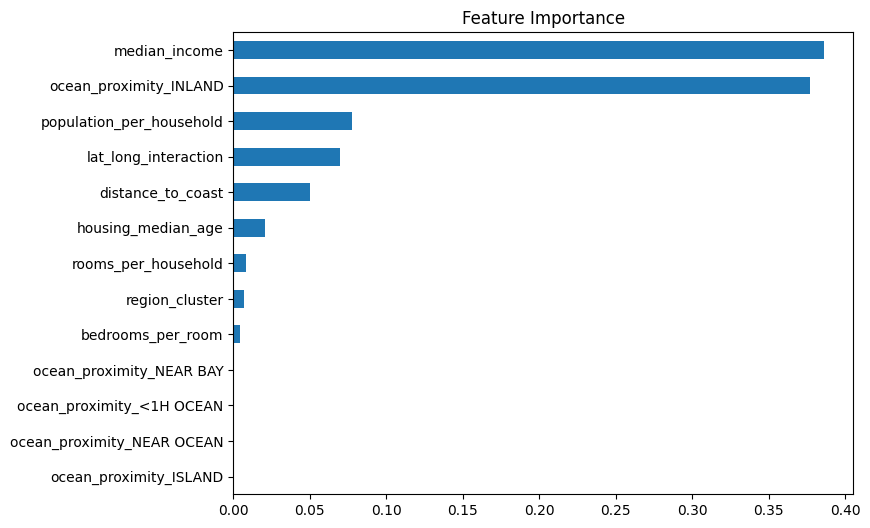

In [97]:
import pandas as pd
import matplotlib.pyplot as plt

importances = pd.Series(best_tree.feature_importances_, index=X.columns)
importances.sort_values(ascending=True).plot(kind='barh', figsize=(8,6))
plt.title("Feature Importance")
plt.show()
